# 05-1. 자동 노이즈 제거 ablation 실험

전처리 단계만 달리한 A-0~A-3을 같은 KoBART 설정과 같은 test set으로 학습·평가한다.

- **A-0**: 원본 document/summary를 복원한 학습 데이터
- **A-1**: A-0에서 `repeat_4gram` 행 제거
- **A-2**: A-1 + URL·재배포 문구·깨진 문자 등 본문 기계 정제
- **A-3**: A-2 + 정확 중복 제거 + document/summary 그룹 split

평가에는 모든 실험에서 `processed_data/04-3_final/test.csv`를 사용한다. 따라서 A-0은 03-2의 원본 test 결과를 대체하지 않으며, 전처리 효과를 공정하게 비교하기 위한 재현 실험이다.

## 1. 설정

처음에는 `RUN_TRAINING=False`로 전체 데이터 구성과 누수 검사를 확인한다. 이상이 없으면 `True`로 바꾸고 실행한다. 이미 완료된 실험은 기본적으로 건너뛰므로 중간에 실행이 끊겨도 이어서 진행할 수 있다.

In [11]:
import gc
import hashlib
import json
import os
import random
import re
import sys
import time
from pathlib import Path

PROJECT = Path(r"C:\Users\KDS-30\Desktop\Projects\06_Team_Project4")
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

RESULTS = PROJECT / "results" / "05-1_noise_ablation"
CLEANED_DIR = PROJECT / "processed_data" / "04-2_cleaned"
FINAL_DIR = PROJECT / "processed_data" / "04-3_final"
REPEAT_ROWS_PATH = PROJECT / "review_data" / "04-2_cleaning" / "excluded_repeat_4gram_rows.csv"
RAW_MANIFEST_PATH = PROJECT / "results" / "03-2_baseline_raw_data" / "split_manifest.csv"
RESULTS.mkdir(parents=True, exist_ok=True)

SEED = 42
MODEL_ID = "gogamza/kobart-base-v2"
MAX_SOURCE_LENGTH = 512
MAX_TARGET_LENGTH = 256
EPOCHS = 5
BATCH_SIZE = 2
LEARNING_RATE = 3e-5
EXPERIMENTS_TO_RUN = ["A0", "A1", "A2", "A3"]
RUN_TRAINING = True  # 데이터 검증 후 학습을 시작할 때만 True
SKIP_COMPLETED = True
SAVE_MODEL = True

print("Python:", sys.version.split()[0])
print("결과 폴더:", RESULTS)

Python: 3.11.9
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-1_noise_ablation


In [12]:
import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import HfApi
from torch import optim
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader, RandomSampler, SequentialSampler, TensorDataset
from transformers import AutoTokenizer, BartForConditionalGeneration

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "CUDA를 사용할 수 없습니다."
print("device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM(GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
VRAM(GB): 7.96


## 2. A-0~A-3 데이터 구성

A-0~A-2의 train/validation 배정은 03-2에서 만든 누수 방지 manifest를 공통으로 사용한다. A-3은 04-3에서 확정한 중복 제거·그룹 split 결과를 그대로 사용한다. test는 네 실험 모두 A-3의 동일한 2,564행으로 고정한다.

In [13]:
required_paths = [
    *(CLEANED_DIR / f"{split}.csv" for split in ["train", "validation", "test"]),
    *(FINAL_DIR / f"{split}.csv" for split in ["train", "validation", "test"]),
    REPEAT_ROWS_PATH,
    RAW_MANIFEST_PATH,
]
missing_paths = [str(path) for path in required_paths if not path.exists()]
assert not missing_paths, f"필요한 파일이 없습니다: {missing_paths}"

base_columns = ["row_id", "title", "document", "summary"]

cleaned_parts = []
for source_split in ["train", "validation", "test"]:
    frame = pd.read_csv(CLEANED_DIR / f"{source_split}.csv")
    assert frame["split"].eq(source_split).all()
    cleaned_parts.append(frame)
cleaned_all = pd.concat(cleaned_parts, ignore_index=True)

repeat_rows = pd.read_csv(REPEAT_ROWS_PATH)
raw_kept = cleaned_all[["row_id", "split", "title", "document_original", "summary"]].rename(
    columns={"document_original": "document"}
)
raw_repeat = repeat_rows[["row_id", "split", "title", "document", "summary"]].copy()
raw_all = pd.concat([raw_kept, raw_repeat], ignore_index=True)
assert len(raw_all) == 27_400
assert raw_all["row_id"].is_unique

manifest = pd.read_csv(RAW_MANIFEST_PATH)[["row_id", "assigned_split"]]
assert manifest["row_id"].is_unique

def apply_baseline_manifest(frame):
    merged = frame.merge(manifest, on="row_id", how="left", validate="one_to_one")
    assert merged["assigned_split"].notna().all()
    return {
        split: merged.loc[merged["assigned_split"].eq(split), base_columns].reset_index(drop=True)
        for split in ["train", "validation"]
    }

a0 = apply_baseline_manifest(raw_all)
repeat_ids = set(repeat_rows["row_id"])
a1 = {
    split: frame.loc[~frame["row_id"].isin(repeat_ids)].reset_index(drop=True)
    for split, frame in a0.items()
}
a2 = apply_baseline_manifest(cleaned_all)
a3 = {
    split: pd.read_csv(FINAL_DIR / f"{split}.csv")[base_columns].reset_index(drop=True)
    for split in ["train", "validation"]
}
common_test = pd.read_csv(FINAL_DIR / "test.csv")[base_columns].reset_index(drop=True)

experiment_frames = {
    "A0": {**a0, "test": common_test},
    "A1": {**a1, "test": common_test},
    "A2": {**a2, "test": common_test},
    "A3": {**a3, "test": common_test},
}
experiment_labels = {
    "A0": "raw_train_common_clean_test",
    "A1": "remove_repeat_4gram",
    "A2": "repeat_removed_and_document_cleaned",
    "A3": "automatic_clean_dedup_group_split",
}

dataset_counts = pd.DataFrame([
    {"experiment": experiment, "description": experiment_labels[experiment],
     **{f"{split}_rows": len(frames[split]) for split in ["train", "validation", "test"]}}
    for experiment, frames in experiment_frames.items()
])
dataset_counts.to_csv(RESULTS / "dataset_counts.csv", index=False, encoding="utf-8-sig")
display(dataset_counts)

,experiment,description,train_rows,validation_rows,test_rows
0,A0,raw_train_common_clean_test,20839,2811,2564
1,A1,remove_repeat_4gram,20058,2605,2564
2,A2,repeat_removed_and_document_cleaned,20058,2605,2564
3,A3,automatic_clean_dedup_group_split,19236,2240,2564


In [14]:
space_pattern = re.compile(r"\s+")

def normalized_values(frame, column):
    return set(frame[column].astype(str).map(lambda value: space_pattern.sub(" ", value).strip()))

leakage_rows = []
common_test_ids = common_test["row_id"].tolist()
common_test_digest = hashlib.sha256(
    "\n".join(common_test_ids).encode("utf-8")
).hexdigest()

for experiment, frames in experiment_frames.items():
    assert frames["test"]["row_id"].tolist() == common_test_ids
    for split, frame in frames.items():
        assert frame["row_id"].is_unique, f"{experiment} {split}: row_id 중복"
        assert frame[["document", "summary"]].notna().all().all()
        assert frame["document"].astype(str).str.strip().ne("").all()
        assert frame["summary"].astype(str).str.strip().ne("").all()

    for column in ["document", "summary"]:
        values = {split: normalized_values(frames[split], column) for split in ["train", "validation", "test"]}
        for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
            overlap = len(values[left] & values[right])
            leakage_rows.append({
                "experiment": experiment, "column": column,
                "left": left, "right": right, "overlap": overlap,
            })

leakage_check = pd.DataFrame(leakage_rows)
assert leakage_check["overlap"].sum() == 0, "split 간 document/summary 중복을 확인하세요."
leakage_check.to_csv(RESULTS / "split_leakage_check.csv", index=False, encoding="utf-8-sig")
display(leakage_check)
print("공통 test 행 수:", len(common_test))
print("공통 test row_id SHA256:", common_test_digest)
print("검증 통과: 모든 실험의 test 동일, split 간 document/summary 중복 0")

,experiment,column,left,right,overlap
0,A0,document,train,validation,0
1,A0,document,train,test,0
2,A0,document,validation,test,0
3,A0,summary,train,validation,0
4,A0,summary,train,test,0
5,A0,summary,validation,test,0
6,A1,document,train,validation,0
7,A1,document,train,test,0
8,A1,document,validation,test,0
9,A1,summary,train,validation,0


공통 test 행 수: 2564
공통 test row_id SHA256: c65a547f703cc84cde13a25f95291d9cf2e45a1f96d4ca830e6b20b6bb6a588f
검증 통과: 모든 실험의 test 동일, split 간 document/summary 중복 0


## 3. 공통 토큰화·학습·평가 함수

각 실험을 시작할 때 seed, 모델, optimizer를 새로 초기화한다. 따라서 이전 실험의 학습 상태가 다음 실험으로 전달되지 않는다.

In [15]:
model_revision = HfApi().model_info(MODEL_ID).sha
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    revision=model_revision,
    clean_up_tokenization_spaces=False,
)
rouge_metric = evaluate.load("rouge")

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

def make_dataset(frame):
    source = tokenizer(
        text=frame["document"].astype(str).tolist(),
        padding="max_length", truncation=True, max_length=MAX_SOURCE_LENGTH,
        return_token_type_ids=False, return_tensors="pt",
    )
    target = tokenizer(
        text_target=frame["summary"].astype(str).tolist(),
        padding="max_length", truncation=True, max_length=MAX_TARGET_LENGTH,
        return_token_type_ids=False, return_tensors="pt",
    )
    labels = target["input_ids"].clone()
    labels[labels == tokenizer.pad_token_id] = -100
    return TensorDataset(source["input_ids"], source["attention_mask"], labels)

def make_loader(dataset, train_mode):
    sampler = RandomSampler(dataset) if train_mode else SequentialSampler(dataset)
    return DataLoader(dataset, sampler=sampler, batch_size=BATCH_SIZE, num_workers=0, pin_memory=True)

def train_one_epoch(model, optimizer, dataloader):
    model.train()
    total_loss = 0.0
    for step, batch in enumerate(dataloader, start=1):
        input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
        optimizer.zero_grad()
        loss = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss
        loss.backward()
        clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
        if step % 500 == 0:
            print(f"  step {step:,}/{len(dataloader):,} | loss {total_loss / step:.4f}")
    return total_loss / len(dataloader)

def evaluate_loss(model, dataloader):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for batch in dataloader:
            input_ids, attention_mask, labels = [tensor.to(device) for tensor in batch]
            total_loss += model(
                input_ids=input_ids, attention_mask=attention_mask, labels=labels
            ).loss.item()
    return total_loss / len(dataloader)

def generate_predictions(model, dataloader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for step, batch in enumerate(dataloader, start=1):
            input_ids, attention_mask, _ = [tensor.to(device) for tensor in batch]
            generated_ids = model.generate(
                input_ids=input_ids, attention_mask=attention_mask,
                max_length=MAX_TARGET_LENGTH, num_beams=1, do_sample=False,
            )
            predictions.extend(tokenizer.batch_decode(
                generated_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False
            ))
            if step % 200 == 0:
                print(f"  generation {step:,}/{len(dataloader):,}")
    return [prediction.strip() for prediction in predictions]

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


## 4. A-0~A-3 순차 학습 및 공통 test 평가

실험별 폴더에 best checkpoint, epoch loss, test 예측, ROUGE 결과가 즉시 저장된다. `SKIP_COMPLETED=True`이면 `test_metrics.json`이 존재하는 실험은 다시 학습하지 않는다.


===== A0: raw_train_common_clean_test =====


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


train / validation / test: 20839 2811 2564
  step 500/10,420 | loss 0.8701
  step 1,000/10,420 | loss 0.7771
  step 1,500/10,420 | loss 0.7376
  step 2,000/10,420 | loss 0.7067
  step 2,500/10,420 | loss 0.6866
  step 3,000/10,420 | loss 0.6704
  step 3,500/10,420 | loss 0.6585
  step 4,000/10,420 | loss 0.6489
  step 4,500/10,420 | loss 0.6395
  step 5,000/10,420 | loss 0.6312
  step 5,500/10,420 | loss 0.6240
  step 6,000/10,420 | loss 0.6199
  step 6,500/10,420 | loss 0.6141
  step 7,000/10,420 | loss 0.6094
  step 7,500/10,420 | loss 0.6040
  step 8,000/10,420 | loss 0.6004
  step 8,500/10,420 | loss 0.5964
  step 9,000/10,420 | loss 0.5932
  step 9,500/10,420 | loss 0.5903
  step 10,000/10,420 | loss 0.5878
A0 epoch 1/5 | train 0.5856 | validation 0.5147 | 31.4분
Saved: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-1_noise_ablation\A0\best_model_state.pt
  step 500/10,420 | loss 0.3844
  step 1,000/10,420 | loss 0.3887
  step 1,500/10,420 | loss 0.3891
  step 2,000/1

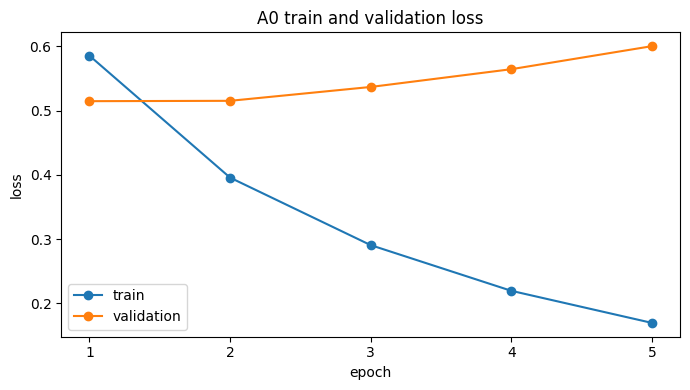

  generation 200/1,282
  generation 400/1,282
  generation 600/1,282
  generation 800/1,282
  generation 1,000/1,282
  generation 1,200/1,282


experiment                                       A0
description             raw_train_common_clean_test
train_rows                                    20839
validation_rows                                2811
test_rows                                      2564
best_epoch                                        1
best_validation_loss                       0.514719
test_loss                                  0.510187
rouge1                                    32.527115
rouge2                                    27.147362
rougeL                                    29.460856
rougeLsum                                 29.426785
Name: A0, dtype: object


===== A1: remove_repeat_4gram =====


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


train / validation / test: 20058 2605 2564
  step 500/10,029 | loss 0.8580
  step 1,000/10,029 | loss 0.7672
  step 1,500/10,029 | loss 0.7197
  step 2,000/10,029 | loss 0.6957
  step 2,500/10,029 | loss 0.6801
  step 3,000/10,029 | loss 0.6656
  step 3,500/10,029 | loss 0.6536
  step 4,000/10,029 | loss 0.6427
  step 4,500/10,029 | loss 0.6348
  step 5,000/10,029 | loss 0.6271
  step 5,500/10,029 | loss 0.6205
  step 6,000/10,029 | loss 0.6144
  step 6,500/10,029 | loss 0.6093
  step 7,000/10,029 | loss 0.6037
  step 7,500/10,029 | loss 0.5998
  step 8,000/10,029 | loss 0.5966
  step 8,500/10,029 | loss 0.5929
  step 9,000/10,029 | loss 0.5890
  step 9,500/10,029 | loss 0.5861
  step 10,000/10,029 | loss 0.5833
A1 epoch 1/5 | train 0.5832 | validation 0.5109 | 29.9분
Saved: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-1_noise_ablation\A1\best_model_state.pt
  step 500/10,029 | loss 0.3755
  step 1,000/10,029 | loss 0.3740
  step 1,500/10,029 | loss 0.3807
  step 2,000/1

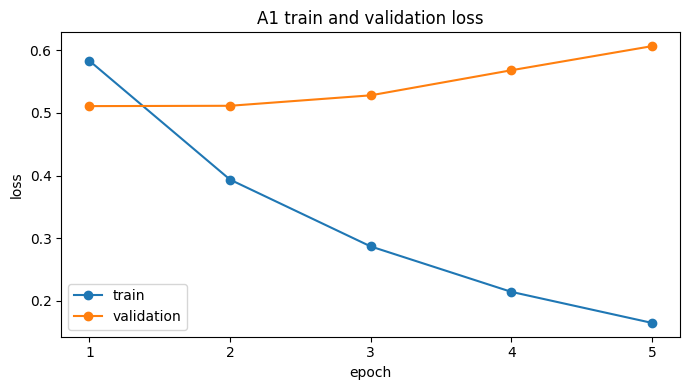

  generation 200/1,282
  generation 400/1,282
  generation 600/1,282
  generation 800/1,282
  generation 1,000/1,282
  generation 1,200/1,282


experiment                               A1
description             remove_repeat_4gram
train_rows                            20058
validation_rows                        2605
test_rows                              2564
best_epoch                                1
best_validation_loss               0.510889
test_loss                          0.509269
rouge1                            40.689391
rouge2                            34.347865
rougeL                            37.301497
rougeLsum                         37.296546
Name: A1, dtype: object


===== A2: repeat_removed_and_document_cleaned =====


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


train / validation / test: 20058 2605 2564
  step 500/10,029 | loss 0.8607
  step 1,000/10,029 | loss 0.7678
  step 1,500/10,029 | loss 0.7211
  step 2,000/10,029 | loss 0.6965
  step 2,500/10,029 | loss 0.6806
  step 3,000/10,029 | loss 0.6660
  step 3,500/10,029 | loss 0.6540
  step 4,000/10,029 | loss 0.6434
  step 4,500/10,029 | loss 0.6353
  step 5,000/10,029 | loss 0.6278
  step 5,500/10,029 | loss 0.6213
  step 6,000/10,029 | loss 0.6152
  step 6,500/10,029 | loss 0.6101
  step 7,000/10,029 | loss 0.6045
  step 7,500/10,029 | loss 0.6007
  step 8,000/10,029 | loss 0.5972
  step 8,500/10,029 | loss 0.5934
  step 9,000/10,029 | loss 0.5896
  step 9,500/10,029 | loss 0.5868
  step 10,000/10,029 | loss 0.5840
A2 epoch 1/5 | train 0.5839 | validation 0.5115 | 30.0분
Saved: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-1_noise_ablation\A2\best_model_state.pt
  step 500/10,029 | loss 0.3780
  step 1,000/10,029 | loss 0.3770
  step 1,500/10,029 | loss 0.3822
  step 2,000/1

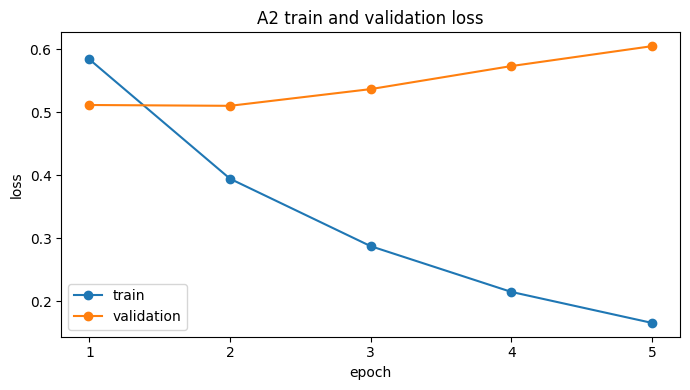

  generation 200/1,282
  generation 400/1,282
  generation 600/1,282
  generation 800/1,282
  generation 1,000/1,282
  generation 1,200/1,282


experiment                                               A2
description             repeat_removed_and_document_cleaned
train_rows                                            20058
validation_rows                                        2605
test_rows                                              2564
best_epoch                                                2
best_validation_loss                               0.510171
test_loss                                          0.510312
rouge1                                            32.965013
rouge2                                             27.48194
rougeL                                             30.02451
rougeLsum                                         30.043241
Name: A2, dtype: object


===== A3: automatic_clean_dedup_group_split =====


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


train / validation / test: 19236 2240 2564
  step 500/9,618 | loss 0.8608
  step 1,000/9,618 | loss 0.7728
  step 1,500/9,618 | loss 0.7328
  step 2,000/9,618 | loss 0.7060
  step 2,500/9,618 | loss 0.6849
  step 3,000/9,618 | loss 0.6697
  step 3,500/9,618 | loss 0.6575
  step 4,000/9,618 | loss 0.6496
  step 4,500/9,618 | loss 0.6415
  step 5,000/9,618 | loss 0.6338
  step 5,500/9,618 | loss 0.6264
  step 6,000/9,618 | loss 0.6216
  step 6,500/9,618 | loss 0.6171
  step 7,000/9,618 | loss 0.6122
  step 7,500/9,618 | loss 0.6077
  step 8,000/9,618 | loss 0.6042
  step 8,500/9,618 | loss 0.5997
  step 9,000/9,618 | loss 0.5962
  step 9,500/9,618 | loss 0.5932
A3 epoch 1/5 | train 0.5925 | validation 0.5163 | 28.4분
Saved: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\05-1_noise_ablation\A3\best_model_state.pt
  step 500/9,618 | loss 0.3914
  step 1,000/9,618 | loss 0.3927
  step 1,500/9,618 | loss 0.3941
  step 2,000/9,618 | loss 0.3960
  step 2,500/9,618 | loss 0.3973
  ste

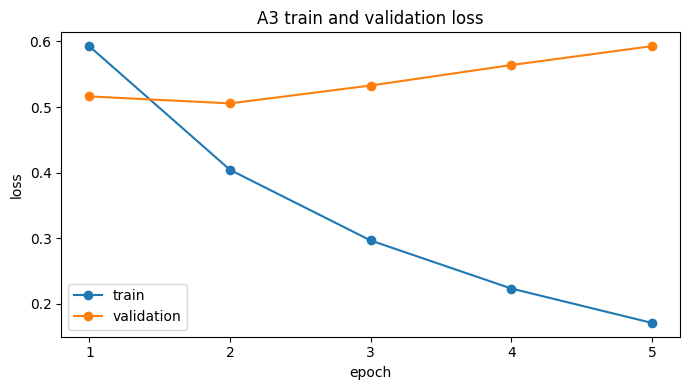

  generation 200/1,282
  generation 400/1,282
  generation 600/1,282
  generation 800/1,282
  generation 1,000/1,282
  generation 1,200/1,282


experiment                                             A3
description             automatic_clean_dedup_group_split
train_rows                                          19236
validation_rows                                      2240
test_rows                                            2564
best_epoch                                              2
best_validation_loss                             0.505654
test_loss                                        0.500127
rouge1                                          41.932051
rouge2                                          35.089334
rougeL                                          38.416714
rougeLsum                                       38.431037
Name: A3, dtype: object

,experiment,description,train_rows,validation_rows,test_rows,best_epoch,best_validation_loss,test_loss,rouge1,rouge2,rougeL,rougeLsum
0,A0,raw_train_common_clean_test,20839,2811,2564,1,0.514719,0.510187,32.527115,27.147362,29.460856,29.426785
1,A1,remove_repeat_4gram,20058,2605,2564,1,0.510889,0.509269,40.689391,34.347865,37.301497,37.296546
2,A2,repeat_removed_and_document_cleaned,20058,2605,2564,2,0.510171,0.510312,32.965013,27.481940,30.024510,30.043241
3,A3,automatic_clean_dedup_group_split,19236,2240,2564,2,0.505654,0.500127,41.932051,35.089334,38.416714,38.431037


In [16]:
result_rows = []

if RUN_TRAINING:
    for experiment in EXPERIMENTS_TO_RUN:
        assert experiment in experiment_frames, f"알 수 없는 실험: {experiment}"
        experiment_dir = RESULTS / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        metrics_path = experiment_dir / "test_metrics.json"

        if SKIP_COMPLETED and metrics_path.exists():
            saved_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
            result_rows.append(saved_metrics)
            print(f"[{experiment}] 완료 결과가 있어 건너뜁니다.")
            continue

        print(f"\n===== {experiment}: {experiment_labels[experiment]} =====")
        reset_seed()
        frames = experiment_frames[experiment]
        train_dataset = make_dataset(frames["train"])
        validation_dataset = make_dataset(frames["validation"])
        test_dataset = make_dataset(frames["test"])
        train_loader = make_loader(train_dataset, train_mode=True)
        validation_loader = make_loader(validation_dataset, train_mode=False)
        test_loader = make_loader(test_dataset, train_mode=False)
        print("train / validation / test:", len(train_dataset), len(validation_dataset), len(test_dataset))

        model = BartForConditionalGeneration.from_pretrained(
            MODEL_ID, revision=model_revision, use_safetensors=True
        ).to(device)
        optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, eps=1e-8)
        model_path = experiment_dir / "best_model_state.pt"
        best_validation_loss = float("inf")
        best_epoch = None
        history = []

        for epoch in range(1, EPOCHS + 1):
            started = time.perf_counter()
            train_loss = train_one_epoch(model, optimizer, train_loader)
            validation_loss = evaluate_loss(model, validation_loader)
            elapsed_minutes = (time.perf_counter() - started) / 60
            history.append({
                "experiment": experiment, "epoch": epoch,
                "train_loss": train_loss, "validation_loss": validation_loss,
                "minutes": elapsed_minutes,
            })
            print(
                f"{experiment} epoch {epoch}/{EPOCHS} | train {train_loss:.4f} | "
                f"validation {validation_loss:.4f} | {elapsed_minutes:.1f}분"
            )
            if validation_loss < best_validation_loss:
                best_validation_loss = validation_loss
                best_epoch = epoch
                torch.save(model.state_dict(), model_path)
                print("Saved:", model_path)

        history_df = pd.DataFrame(history)
        history_df.to_csv(experiment_dir / "loss_history.csv", index=False, encoding="utf-8-sig")
        plt.figure(figsize=(7, 4))
        plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="train")
        plt.plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="validation")
        plt.xlabel("epoch")
        plt.ylabel("loss")
        plt.title(f"{experiment} train and validation loss")
        plt.xticks(history_df["epoch"])
        plt.legend()
        plt.tight_layout()
        plt.savefig(experiment_dir / "loss_curve.png", dpi=160)
        plt.show()

        model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
        test_loss = evaluate_loss(model, test_loader)
        predictions = generate_predictions(model, test_loader)
        references = frames["test"]["summary"].astype(str).tolist()
        rouge_scores = rouge_metric.compute(
            predictions=predictions, references=references,
            tokenizer=lambda text: text.split(), use_stemmer=False,
        )
        metrics = {
            "experiment": experiment,
            "description": experiment_labels[experiment],
            "train_rows": len(frames["train"]),
            "validation_rows": len(frames["validation"]),
            "test_rows": len(frames["test"]),
            "best_epoch": best_epoch,
            "best_validation_loss": best_validation_loss,
            "test_loss": test_loss,
            **{name: score * 100 for name, score in rouge_scores.items()},
        }
        metrics_path.write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
        prediction_df = frames["test"].copy()
        prediction_df["prediction"] = predictions
        prediction_df.to_csv(experiment_dir / "test_predictions.csv", index=False, encoding="utf-8-sig")
        result_rows.append(metrics)
        display(pd.Series(metrics, name=experiment))

        if not SAVE_MODEL:
            model_path.unlink(missing_ok=True)
        del model, optimizer, train_dataset, validation_dataset, test_dataset
        del train_loader, validation_loader, test_loader
        gc.collect()
        torch.cuda.empty_cache()

    experiment_results = pd.DataFrame(result_rows).sort_values("experiment").reset_index(drop=True)
    experiment_results.to_csv(RESULTS / "experiment_results.csv", index=False, encoding="utf-8-sig")
    display(experiment_results)
else:
    print("RUN_TRAINING=False: 데이터 구성과 누수 검사까지만 완료했습니다.")

In [17]:
run_config = {
    "model_id": MODEL_ID,
    "model_revision": model_revision,
    "seed": SEED,
    "max_source_length": MAX_SOURCE_LENGTH,
    "max_target_length": MAX_TARGET_LENGTH,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "experiments_to_run": EXPERIMENTS_TO_RUN,
    "experiment_labels": experiment_labels,
    "common_test_path": str(FINAL_DIR / "test.csv"),
    "common_test_rows": len(common_test),
    "common_test_row_id_sha256": common_test_digest,
    "generation": {"num_beams": 1, "do_sample": False},
}
(RESULTS / "run_config.json").write_text(
    json.dumps(run_config, ensure_ascii=False, indent=2), encoding="utf-8"
)

print("저장 예정/완료 파일:")
for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

저장 예정/완료 파일:
- results\05-1_noise_ablation\A0\best_model_state.pt
- results\05-1_noise_ablation\A0\loss_curve.png
- results\05-1_noise_ablation\A0\loss_history.csv
- results\05-1_noise_ablation\A0\test_metrics.json
- results\05-1_noise_ablation\A0\test_predictions.csv
- results\05-1_noise_ablation\A1\best_model_state.pt
- results\05-1_noise_ablation\A1\loss_curve.png
- results\05-1_noise_ablation\A1\loss_history.csv
- results\05-1_noise_ablation\A1\test_metrics.json
- results\05-1_noise_ablation\A1\test_predictions.csv
- results\05-1_noise_ablation\A2\best_model_state.pt
- results\05-1_noise_ablation\A2\loss_curve.png
- results\05-1_noise_ablation\A2\loss_history.csv
- results\05-1_noise_ablation\A2\test_metrics.json
- results\05-1_noise_ablation\A2\test_predictions.csv
- results\05-1_noise_ablation\A3\best_model_state.pt
- results\05-1_noise_ablation\A3\loss_curve.png
- results\05-1_noise_ablation\A3\loss_history.csv
- results\05-1_noise_ablation\A3\test_metrics.json
- results\05-1_no